# 06 — Notebook 03 hypotheses on the 54-product universe

## Results and scope

The original four hypothesis families, momentum and breakout are examined on the frozen 54-product set. Train is **2016–2019**; test is **2020–18 October 2021**. Thresholds are estimated on train and frozen. At the fixed test slice h=5 minutes/delay=1 minute, **6/9 aggregate contrasts** pass BY and all six indicate reversal. Across 486 product/setup tests, 54 indicate reversal, 329 are not detected and 103 have insufficient data. These counts are not profitable-product or trading-performance counts.

For strong returns with high volume, the test contrast falls from **−2.49 bp** without delay to **−0.65 bp** after one minute. For normalized-return extremes it falls from **−2.81 to −0.52 bp**. These are differences in conditional future price changes, not strategy returns.

This is an event study. It creates no trades, positions, sizing, PnL, equity, Sharpe or execution assumptions. Forecasting is in notebook 07; the separate fee/execution experiment is in notebook 08.

## Original conditions

1. Return + volume: positive/negative return extremes (Q90/Q10) with high/low volume (Q80/Q20).
2. Range + volume: large `High−Low` (Q90), close-to-close return sign, high/low volume.
3. Volatility regime: return extremes with high/low trailing-30-minute volatility (Q80/Q20).
4. Normalized return: extremes of the original `simple_return / rolling_30m_log_std` (Q90/Q10).

Momentum/reversal interpretations use horizons 1/2/3/5. Later notebook 03 blocks contain AR/MA/ARMA, GARCH/EGARCH/GJR, logistic probabilities, two-layer S0–S9 and volatility-filtered momentum/breakout. The registry below maps each block to its current stage.

The earlier first-stage protocol used 30% of dates for calibration and ordinary t-tests on overlapping events. This stage explicitly uses calendar train/test, daily HAC (20/60 dates) and BY. No 77-product performance is relabelled as a 54-product result. Positive `E[R_future|positive event]−E[R_future|negative event]` indicates continuation, negative reversal. This is association, not causation; the two interpretations are not separate discoveries.


In [1]:
from pathlib import Path
import json, hashlib, time
import numpy as np
import pandas as pd
from scipy.stats import norm,false_discovery_control
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd(); INPUT=ROOT/'artifacts/research_54/statistics/manifest.json'
OUT=ROOT/'artifacts/research_54/hypotheses'
for p in [OUT,OUT/'figures',OUT/'signals']: p.mkdir(parents=True,exist_ok=True)
manifest=json.loads(INPUT.read_text()); files=manifest['files']; assert len(files)==54
SPLIT=pd.Timestamp('2020-01-01'); END=pd.Timestamp('2022-01-01')
HORIZONS=[1,2,3,5]; DELAYS=[0,1]; PERIODS=['train','test','2020','2021']
MIN_DATES=90
def digest(path):
    with Path(path).open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()
input_hash=digest(INPUT)
def show(df,title,rows=15):
    display(df.head(rows).style.hide(axis='index').format({c:'{:.2e}' for c in df.columns if c in ['p','q_by']},precision=5,na_rep='NA').set_caption(title))
    if len(df)>rows: print(f"Showing {rows}/{len(df)} rows; the CSV contains every row.")
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.dpi':120})
COLORS={'train':'#25638c','test':'#c17229'}
def savefig(fig,name):
    fig.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight'); plt.show()
registry=pd.DataFrame([
 ('03 cells 5–39',"Four families / seven conditions","06: original conditions, new calibration and inference"),
 ('03 cells 40–61','AR(1), MA(1), ARMA(1,1), GARCH, EWMA','07: fixed train 2016–2019; test forecast quality'),
 ('03 cells 62–77',"AR(2), standardized ARMA, logistic, EGARCH/GJR","07: separate forecast layers and causal training features"),
 ('S0','Momentum5 + fixed size',"06: momentum5 direction only; no sizing"),
 ('S1–S3','Raw ARMA + GARCH/EGARCH/GJR sizing',"07: direction and variance estimated separately; sizing in 08"),
 ('S4–S6','Standardized ARMA + corresponding variance sizing',"07: standardization from inner-training forecasts; sizing in 08"),
 ('S7–S9','Logistic + GARCH/EGARCH/GJR sizing',"07: probabilities and calibration; trading rules in 08"),
 ('Breakout','Previous 20-bar high/low, optional volatility expansion',"06: baseline breakout; 07: predictive regime diagnostics"),
 ('03 cells 78–109','Position/cost grid, net performance, equity',"Not calculated in 06; explicit product fees and execution are evaluated separately in 08")
],columns=["Source","Hypothesis / strategy","Current stage"])
registry.to_csv(OUT/'notebook03_strategy_registry.csv',index=False)
show(registry,"Registry of approaches examined in 03",12)

Source,Hypothesis / strategy,Current stage
03 cells 5–39,Four families / seven conditions,"06: original conditions, new calibration and inference"
03 cells 40–61,"AR(1), MA(1), ARMA(1,1), GARCH, EWMA",07: fixed train 2016–2019; test forecast quality
03 cells 62–77,"AR(2), standardized ARMA, logistic, EGARCH/GJR",07: separate forecast layers and causal training features
S0,Momentum5 + fixed size,06: momentum5 direction only; no sizing
S1–S3,Raw ARMA + GARCH/EGARCH/GJR sizing,07: direction and variance estimated separately; sizing in 08
S4–S6,Standardized ARMA + corresponding variance sizing,07: standardization from inner-training forecasts; sizing in 08
S7–S9,Logistic + GARCH/EGARCH/GJR sizing,07: probabilities and calibration; trading rules in 08
Breakout,"Previous 20-bar high/low, optional volatility expansion",06: baseline breakout; 07: predictive regime diagnostics
03 cells 78–109,"Position/cost grid, net performance, equity",Not calculated in 06; explicit product fees and execution are evaluated separately in 08


### Exact original conditions

Notebook 03 cell 8's conditions are retained. `momentum5` is the sign of the last five log returns. Breakout compares the current close with the previous 20 bars' highs/lows, excluding the current bar. Tied quantiles are not manually separated; high/low overlaps are exported.


In [2]:
def strong_moves(frame, q):
    r = frame["simple_return"]
    return {1: r.ge(q["r90"]) & r.gt(0), -1: r.le(q["r10"]) & r.lt(0)}

def return_volume_signals(frame, q):
    moves = strong_moves(frame, q)
    regimes = {"return_high_volume": frame.Volume.ge(q["v80"]),
               "return_low_volume": frame.Volume.le(q["v20"])}
    return {(setup, direction): condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def range_volume_signals(frame, q):
    large = frame.bar_range.ge(q["range90"])
    moves = {1: frame.simple_return.gt(0), -1: frame.simple_return.lt(0)}
    regimes = {"range_high_volume": frame.Volume.ge(q["v80"]),
               "range_low_volume": frame.Volume.le(q["v20"])}
    return {(setup, direction): large & condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def volatility_signals(frame, q):
    moves = strong_moves(frame, q)
    regimes = {"return_high_volatility": frame.rolling_30m_volatility.ge(q["vol80"]),
               "return_low_volatility": frame.rolling_30m_volatility.le(q["vol20"])}
    return {(setup, direction): condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def normalized_signals(frame, q):
    z = frame.normalized_return
    return {("normalized_return", 1): z.ge(q["z90"]) & z.gt(0),
            ("normalized_return", -1): z.le(q["z10"]) & z.lt(0)}

SETUPS={
    "return_high_volume":("Return + Volume","High Volume"),
    "return_low_volume":("Return + Volume","Low Volume"),
    "range_high_volume":("Bar Range + Volume","High Volume"),
    "range_low_volume":("Bar Range + Volume","Low Volume"),
    "return_high_volatility":("Volatility Regime","High Volatility"),
    "return_low_volatility":("Volatility Regime","Low Volatility"),
    "normalized_return":("Normalized Return","Calibration extremes")}
VARIANTS={"momentum":"Momentum","reversal":"Reversal"}
SIDES={"long":"Long","short":"Short","combined":"Combined"}

In [3]:
QUANTILE_RULES={'r10':('simple_return',.1),'r90':('simple_return',.9),'v20':('Volume',.2),'v80':('Volume',.8),
    'range90':('bar_range',.9),'vol20':('rolling_30m_volatility',.2),'vol80':('rolling_30m_volatility',.8),
    'z10':('normalized_return',.1),'z90':('normalized_return',.9)}
ALL_SETUPS=[*SETUPS,'momentum5','breakout20']
def construct_signals(frame,q):
    conditions={}
    for function in [return_volume_signals,range_volume_signals,volatility_signals,normalized_signals]:
        conditions.update(function(frame,q))
    group=frame.groupby('segment_id',sort=False)
    mom=group.log_return.rolling(5,min_periods=5).sum().droplevel(0).reindex(frame.index)
    upper=group.High.transform(lambda x:x.shift(1).rolling(20,min_periods=20).max())
    lower=group.Low.transform(lambda x:x.shift(1).rolling(20,min_periods=20).min())
    conditions.update({('momentum5',1):mom>0,('momentum5',-1):mom<0,
                       ('breakout20',1):frame.Close>upper,('breakout20',-1):frame.Close<lower})
    return {key:mask.to_numpy() for key,mask in conditions.items()}

def future_response(frame,horizon,delay):
    # A response target, not an assumed execution interval. Require a complete finite return path.
    n=len(frame); distance=horizon+delay; values=np.full(n,np.nan)
    if n<=distance: return values,np.full(n,np.datetime64('NaT'),dtype='datetime64[us]')
    ids=frame.segment_id.to_numpy(); r=frame.log_return.to_numpy(); close=frame.Close.to_numpy()
    start=np.arange(n-distance); valid=ids[start]==ids[start+distance]
    for step in range(1,distance+1): valid &= np.isfinite(r[start+step])
    valid &= np.isfinite(close[start+delay])&(close[start+delay]>0)&np.isfinite(close[start+distance])&(close[start+distance]>0)
    ix=start[valid]; values[ix]=close[ix+distance]/close[ix+delay]-1
    target_end=np.full(n,np.datetime64('NaT'),dtype='datetime64[us]'); target_end[ix]=frame.date.to_numpy()[ix+distance]
    return values,target_end

def hac_se(scores,min_dates,active):
    result=[]
    for bandwidth in [20,60]:
        B=min(bandwidth,len(scores)-1); meat=np.sum(scores*scores)
        for k in range(1,B+1): meat+=2*(1-k/(B+1))*np.sum(scores[k:]*scores[:-k])
        result.append(np.sqrt(max(0,meat)*active/max(1,active-1)))
    return max(result) if active>=min_dates else np.nan

def event_contrast(target,up,down,day,D):
    results={}; scores=np.zeros(D); active_dates=[]
    for label,mask,mult in [('up',up,1),('down',down,-1)]:
        valid=mask&np.isfinite(target); x=target[valid]; g=day[valid]; n=len(x)
        mu=x.mean() if n else np.nan; active=len(np.unique(g)); active_dates.append(active)
        results.update({f'n_{label}':n,f'dates_{label}':active,f'mean_{label}':mu,
            f'zero_share_{label}':np.mean(x==0) if n else np.nan,
            f'positive_share_{label}':np.mean(x>0) if n else np.nan,
            f'continuation_nonzero_{label}':np.mean(np.sign(x[x!=0])==mult) if np.any(x!=0) else np.nan})
        if n: scores+=mult*np.bincount(g,weights=(x-mu)/n,minlength=D)
    difference=results['mean_up']-results['mean_down']
    se=hac_se(scores,MIN_DATES,min(active_dates)) if min(results['n_up'],results['n_down'])>=100 else np.nan
    results.update(contrast=difference,se=se,ci95_low=difference-1.96*se,ci95_high=difference+1.96*se,
                   p=2*norm.sf(abs(difference/se)) if se>0 else np.nan)
    results['status']='ok' if np.isfinite(results['p']) else 'insufficient_events_dates_or_variance'
    return results,scores

### Chronology checks

With delay 0 the target is `Close[t+h]/Close[t]−1`; with delay 1 it is `Close[t+1+h]/Close[t+1]−1`. Delay 1 tests persistence after waiting a minute without prescribing an execution price. The complete target stays inside one segment and the relevant train/test/year window. Targets cannot feed back into signals.


In [4]:
threshold_rows=[]; quality_rows=[]; results=[]; global_scores={}; signal_records=[]; examples=[]
started=time.monotonic()
for number,record in enumerate(manifest['features'],1):
    filename=record['file']; path=ROOT/record['path']; assert digest(path)==record['sha256']
    frame=pd.read_parquet(path).rename(columns={'open':'Open','high':'High','low':'Low','close':'Close','volume':'Volume'})
    train=frame.date<SPLIT
    q={key:frame.loc[train,field].replace([np.inf,-np.inf],np.nan).quantile(prob) for key,(field,prob) in QUANTILE_RULES.items()}
    assert frame.loc[train,'date'].max()<SPLIT
    threshold_rows.append(dict(file=filename,train_rows=int(train.sum()),train_dates=frame.loc[train,'date'].dt.normalize().nunique(),
        train_start=frame.loc[train,'date'].min(),train_end=frame.loc[train,'date'].max(),**q))
    signals=construct_signals(frame,q)
    # Every stored signal is a known-at-t feature; do not import future labels here.
    saved=frame[['date','ID','symbol','segment_id','period']].copy()
    for setup in ALL_SETUPS:
        assert not np.any(signals[(setup,1)]&signals[(setup,-1)])
        saved[setup]=signals[(setup,1)].astype('int8')-signals[(setup,-1)].astype('int8')
    signal_path=OUT/'signals'/(Path(filename).stem+'.parquet'); saved.to_parquet(signal_path,index=False,compression='zstd')
    signal_records.append(dict(file=filename,path=str(signal_path.relative_to(ROOT)),sha256=digest(signal_path)))
    quality_rows.append(dict(file=filename,volume_regime_overlap_train=int((train&frame.Volume.ge(q['v80'])&frame.Volume.le(q['v20'])).sum()),
        volume_regime_overlap_test=int((~train&frame.Volume.ge(q['v80'])&frame.Volume.le(q['v20'])).sum()),
        volatility_regime_overlap_train=int((train&frame.rolling_30m_volatility.ge(q['vol80'])&frame.rolling_30m_volatility.le(q['vol20'])).sum()),
        missing_thresholds=int(pd.Series(q).isna().sum())))
    for delay in DELAYS:
        for horizon in HORIZONS:
            target,target_end=future_response(frame,horizon,delay)
            # Independent endpoint/time checks across the dataset, not only first rows.
            ix=np.flatnonzero(np.isfinite(target))
            for i in ix[np.linspace(0,len(ix)-1,min(10,len(ix)),dtype=int)]:
                assert frame.segment_id.iloc[i]==frame.segment_id.iloc[i+horizon+delay]
                assert frame.date.iloc[i+horizon+delay]-frame.date.iloc[i]==pd.Timedelta(minutes=horizon+delay)
                np.testing.assert_allclose(target[i],frame.Close.iloc[i+horizon+delay]/frame.Close.iloc[i+delay]-1,atol=1e-14)
            for period in PERIODS:
                start=pd.Timestamp('2016-01-01') if period=='train' else SPLIT if period in ['test','2020'] else pd.Timestamp('2021-01-01')
                stop=SPLIT if period=='train' else pd.Timestamp('2021-01-01') if period=='2020' else END
                selection=frame.date.ge(start)&frame.date.lt(stop)
                dates,day=np.unique(frame.loc[selection,'date'].dt.normalize().to_numpy(),return_inverse=True)
                y=target[selection]; end=target_end[selection]; y=np.where(end<np.datetime64(stop),y,np.nan)
                for setup in ALL_SETUPS:
                    up=signals[(setup,1)][selection]; down=signals[(setup,-1)][selection]
                    result,scores=event_contrast(y,up,down,day,len(dates))
                    result.update(file=filename,period=period,setup=setup,horizon=horizon,delay=delay,signals_up=int(up.sum()),signals_down=int(down.sum()))
                    results.append(result)
                    key=(period,setup,horizon,delay)
                    global_scores.setdefault(key,[]).append((filename,result['contrast'],pd.Series(scores,index=pd.DatetimeIndex(dates)),result['status']))
                    if period=='test' and delay==1 and horizon==5:
                        for side,mask in [('up',up),('down',down)]:
                            chosen=np.flatnonzero(mask&np.isfinite(y))[:1]
                            original=np.flatnonzero(selection.to_numpy())[chosen]
                            for i in original: examples.append(dict(file=filename,setup=setup,side=side,ID=int(frame.ID.iloc[i]),date=frame.date.iloc[i],
                                target_end=target_end[i],horizon=horizon,delay=delay,response=target[i]))
    if number%9==0 or number==54: print(f"{number}/54: conditions and future responses, {time.monotonic()-started:.0f} s",flush=True)
results=pd.DataFrame(results); thresholds=pd.DataFrame(threshold_rows); quality=pd.DataFrame(quality_rows)
results['q_by']=np.nan
for period,ix in results.groupby('period').groups.items():
    ps=results.loc[ix,'p']; results.loc[ix,'q_by']=np.where(ps.notna(),false_discovery_control(ps.fillna(1).to_numpy(),method='by'),np.nan)
results['evidence']=np.select([results.q_by.isna(),(results.q_by<.05)&(results.contrast>0),(results.q_by<.05)&(results.contrast<0)],
    ['insufficient','momentum','reversal'],default='not_detected')
aggregate=[]
for key,parts in global_scores.items():
    period,setup,horizon,delay=key
    all_defined=[p for p in parts if np.isfinite(p[1])]
    defined=[p for p in all_defined if p[3]=='ok']
    means=np.array([p[1] for p in defined]); mean=means.mean() if len(means) else np.nan
    # Calendar-aligned score sums retain contemporaneous cross-file covariance; equal file weights.
    matrix=pd.concat([p[2] for p in defined],axis=1,sort=True).fillna(0.) if defined else pd.DataFrame()
    score=matrix.sum(axis=1).to_numpy()/max(1,len(defined))
    se=hac_se(score,MIN_DATES,int((matrix.abs().sum(axis=1)>0).sum()))
    aggregate.append(dict(period=period,setup=setup,horizon=horizon,delay=delay,files=len(defined),all_defined_files=len(all_defined),all_defined_mean=np.mean([p[1] for p in all_defined]) if all_defined else np.nan,contrast=mean,se=se,
        ci95_low=mean-1.96*se,ci95_high=mean+1.96*se,p=2*norm.sf(abs(mean/se)) if se>0 else np.nan,
        median_file_contrast=np.median(means) if len(means) else np.nan,positive_files=int((means>0).sum()),negative_files=int((means<0).sum())))
aggregate=pd.DataFrame(aggregate); aggregate['q_by']=np.nan
for period,ix in aggregate.groupby('period').groups.items():
    ps=aggregate.loc[ix,'p']; aggregate.loc[ix,'q_by']=np.where(ps.notna(),false_discovery_control(ps.fillna(1).to_numpy(),method='by'),np.nan)
for name,table in {'results_by_file':results,'equal_file_summary':aggregate,'train_thresholds':thresholds,'regime_quality':quality,'response_examples':pd.DataFrame(examples)}.items():
    table.to_csv(OUT/(name+'.csv'),index=False)
assert set(results.file)==set(files) and len(results)==54*len(PERIODS)*len(ALL_SETUPS)*len(HORIZONS)*len(DELAYS)
assert ((results.n_up<=results.signals_up)&(results.n_down<=results.signals_down)).all()
print("All 54 files checked; unknown future prices remain coverage failures rather than zero targets.")

9/54: conditions and future responses, 17 s


18/54: conditions and future responses, 33 s


27/54: conditions and future responses, 48 s


36/54: conditions and future responses, 61 s


45/54: conditions and future responses, 74 s


54/54: conditions and future responses, 85 s


All 54 files checked; unknown future prices remain coverage failures rather than zero targets.


## Dependence direction and stability

Charts show **basis points of the difference between two conditional mean future price changes**, not strategy returns (1 bp=0.0001). Product weights are equal. Intervals address time dependence and synchronous product movements, while retrospective universe bias remains. Training values describe in-sample associations under training-estimated thresholds.

Inferential aggregation requires the same minimum coverage as individual tests: 100 events and 90 dates for each direction, and defined variance. The participating count is explicit; every product remains in the per-file table. `all_defined_files` and `all_defined_mean` provide a separate descriptive summary without this inference filter.

**The inferential subset can change across periods and horizons; a train/test contrast difference is not a pure time effect.** At h=5/delay=1:

| Condition | Train files | Test files |
|---|---:|---:|
| return_low_volume | 40 | 30 |
| range_low_volume | 4 | 6 |
| return_low_volatility | 44 | 23 |


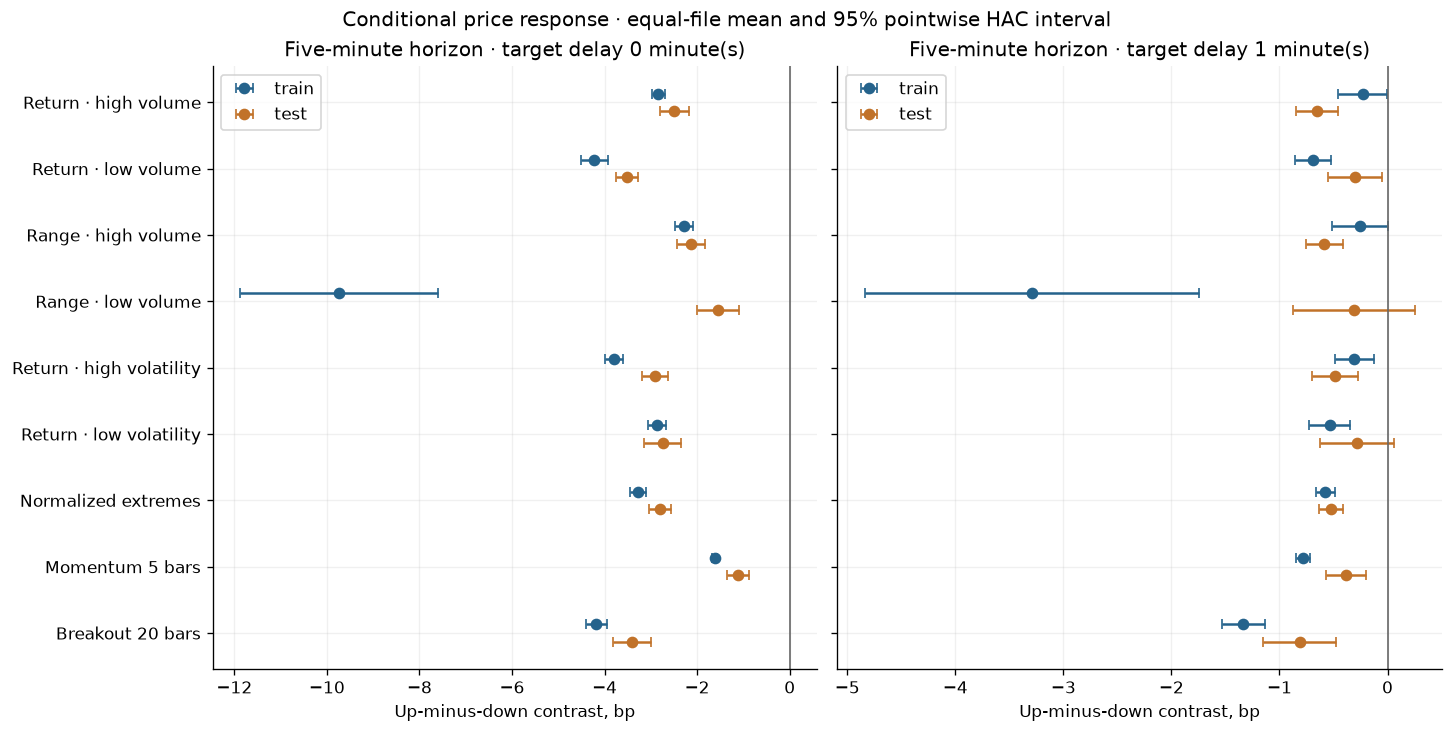

setup,files,contrast,ci95_low,ci95_high,q_by,positive_files,negative_files
return_high_volume,54,-0.64980,-0.84330,-0.45630,3.69e-10,8,46
return_low_volume,30,-0.30376,-0.55421,-0.05331,9.69e-02,11,19
range_high_volume,54,-0.58411,-0.75271,-0.41550,9.33e-11,5,49
range_low_volume,6,-0.31094,-0.87187,0.24999,1.00e+00,2,4
return_high_volatility,54,-0.48532,-0.70074,-0.26990,6.65e-05,10,44
return_low_volatility,23,-0.27960,-0.62052,0.06132,5.64e-01,9,14
normalized_return,54,-0.52034,-0.63294,-0.40774,1.30e-18,4,50
momentum5,54,-0.38578,-0.57074,-0.20081,2.82e-04,10,44
breakout20,54,-0.81437,-1.14813,-0.48062,1.19e-05,8,46


In [5]:
labels={'return_high_volume':'Return · high volume','return_low_volume':'Return · low volume','range_high_volume':'Range · high volume',
        'range_low_volume':'Range · low volume','return_high_volatility':'Return · high volatility','return_low_volatility':'Return · low volatility',
        'normalized_return':'Normalized extremes','momentum5':'Momentum 5 bars','breakout20':'Breakout 20 bars'}
fig,axes=plt.subplots(1,2,figsize=(12,6),sharey=True,layout='constrained')
for ax,delay in zip(axes,DELAYS):
    for period,offset in [('train',-.13),('test',.13)]:
        p=aggregate.query('period==@period and horizon==5 and delay==@delay').set_index('setup').reindex(ALL_SETUPS)
        ax.errorbar(p.contrast*1e4,np.arange(len(ALL_SETUPS))+offset,xerr=p.se*1.96e4,fmt='o',capsize=3,color=COLORS[period],label=period)
    ax.axvline(0,color='#666',lw=1); ax.set_yticks(np.arange(len(ALL_SETUPS)),[labels[x] for x in ALL_SETUPS])
    ax.set(title=f"Five-minute horizon · target delay {delay} minute(s)",xlabel="Up-minus-down contrast, bp"); ax.legend()
axes[0].invert_yaxis()
fig.suptitle("Conditional price response · equal-file mean and 95% pointwise HAC interval")
savefig(fig,'conditional_response')
view=aggregate.query('period=="test" and horizon==5 and delay==1').copy()
for field in ['contrast','ci95_low','ci95_high','median_file_contrast']: view[field]*=1e4
show(view[['setup','files','contrast','ci95_low','ci95_high','q_by','positive_files','negative_files']],
     "Test, h=5 / delay=1: contrast and interval, bp",12)

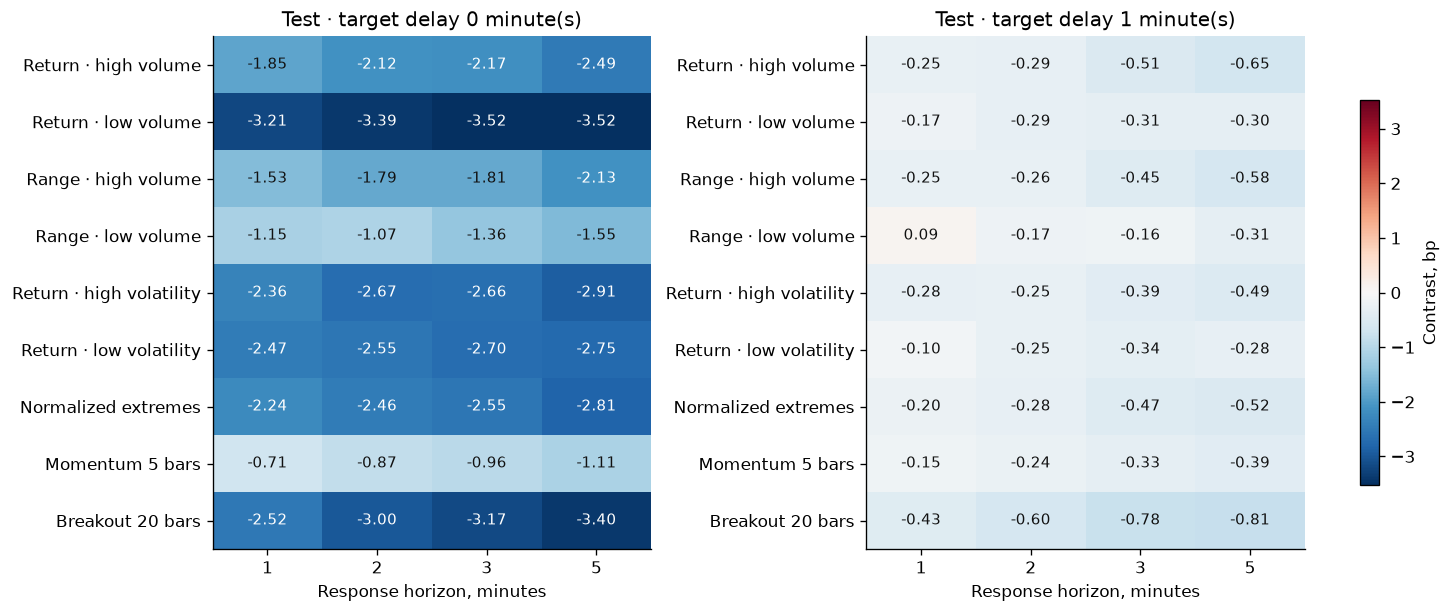

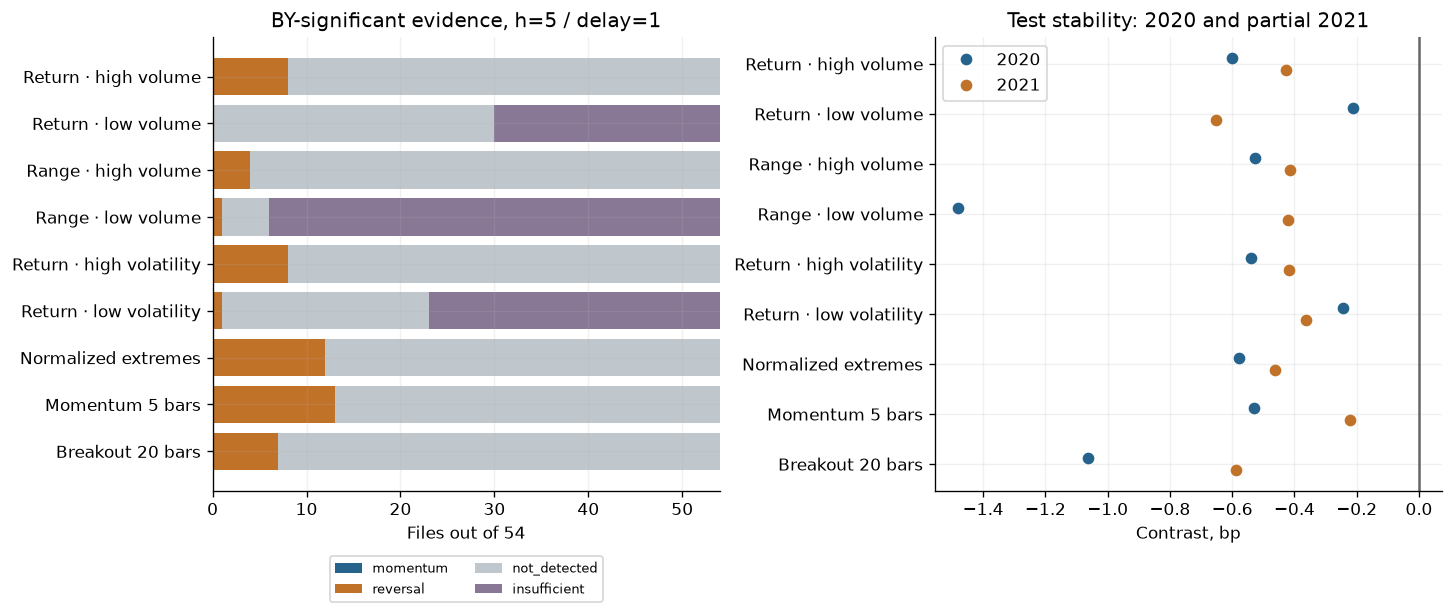

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,delay in zip(axes,DELAYS):
    part=aggregate.query('period=="test" and delay==@delay')
    mat=part.pivot(index='setup',columns='horizon',values='contrast').reindex(index=ALL_SETUPS,columns=HORIZONS)*1e4
    limit=max(abs(aggregate.query('period=="test"').contrast.min()),abs(aggregate.query('period=="test"').contrast.max()))*1e4
    im=ax.imshow(mat,vmin=-limit,vmax=limit,cmap='RdBu_r',aspect='auto'); ax.grid(False)
    ax.set_xticks(range(4),HORIZONS); ax.set_yticks(range(9),[labels[x] for x in ALL_SETUPS])
    for i in range(9):
        for j in range(4): ax.text(j,i,f'{mat.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,color='white' if abs(mat.iloc[i,j])>.55*limit else '#111')
    ax.set(title=f"Test · target delay {delay} minute(s)",xlabel="Response horizon, minutes")
fig.colorbar(im,ax=axes,label="Contrast, bp",shrink=.75)
savefig(fig,'horizon_response')
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
p=results.query('period=="test" and horizon==5 and delay==1')
tab=pd.crosstab(p.setup,p.evidence).reindex(index=ALL_SETUPS,columns=['momentum','reversal','not_detected','insufficient'],fill_value=0)
left=np.zeros(9)
for label,color in [('momentum','#25638c'),('reversal','#c17229'),('not_detected','#bfc7cc'),('insufficient','#887896')]:
    axes[0].barh(range(9),tab[label],left=left,label=label,color=color); left+=tab[label].to_numpy()
axes[0].set_yticks(range(9),[labels[x] for x in ALL_SETUPS]); axes[0].invert_yaxis(); axes[0].set(xlabel="Files out of 54",title='BY-significant evidence, h=5 / delay=1')
axes[0].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.13),ncol=2)
for period,offset,color in [('2020',-.12,'#25638c'),('2021',.12,'#c17229')]:
    p=aggregate.query('period==@period and horizon==5 and delay==1').set_index('setup').reindex(ALL_SETUPS)
    axes[1].plot(p.contrast*1e4,np.arange(9)+offset,'o',label=period,color=color)
axes[1].axvline(0,color='#666'); axes[1].set_yticks(range(9),[labels[x] for x in ALL_SETUPS]); axes[1].invert_yaxis()
axes[1].set(xlabel="Contrast, bp",title="Test stability: 2020 and partial 2021"); axes[1].legend()
savefig(fig,'evidence_and_year_stability')

### All 54 products

The displayed slice fixes h=5 and delay=1. Full CSVs retain the other horizons and both event directions. `not_detected` does not prove absence of an effect; rare-event coverage failures remain explicit.


In [7]:
table=results.query('period=="test" and horizon==5 and delay==1').pivot(index='file',columns='setup',values='contrast').reindex(index=files,columns=ALL_SETUPS)*1e4
table.to_csv(OUT/'test_5m_delay1_contrast_bp_by_file.csv')
display(table.style.format('{:.3f}',na_rep='NA').set_caption("Up-minus-down contrast (bp), 54 files"))
show(quality.loc[(quality.volume_regime_overlap_train>0)|(quality.missing_thresholds>0)],"Quantile ties / unavailable thresholds")

setup,return_high_volume,return_low_volume,range_high_volume,range_low_volume,return_high_volatility,return_low_volatility,normalized_return,momentum5,breakout20
file,,,,,,,,,
RB9999.XSGE.csv,-2.409,0.004,-2.331,-0.319,-0.162,0.377,-1.027,-0.575,-1.087
I9999.XDCE.csv,-3.533,-0.517,-3.075,-1.075,-1.126,-2.502,-1.310,-1.508,-1.577
SC9999.XINE.csv,-0.283,-0.478,-0.779,-4.830,-0.504,0.891,0.191,0.089,0.738
NI9999.XSGE.csv,-0.468,-0.595,-0.465,0.204,0.030,0.518,-0.418,0.095,-0.957
J9999.XDCE.csv,0.090,-0.282,1.081,-1.095,-0.955,-0.846,-0.564,-0.324,-0.284
RU9999.XSGE.csv,-0.711,-0.827,-0.424,NA,0.172,1.613,-0.041,-0.408,0.163
IF9999.CCFX.csv,-1.041,41.358,-0.715,41.358,-1.270,0.074,-1.546,-0.598,-1.607
AU9999.XSGE.csv,-0.133,0.024,-0.050,-0.594,-0.181,0.204,0.145,0.103,-0.055
CU9999.XSGE.csv,-0.527,-0.205,-0.830,0.492,-0.209,1.298,-0.063,-0.006,-0.156


file,volume_regime_overlap_train,volume_regime_overlap_test,volatility_regime_overlap_train,missing_thresholds


## Interpretation and next stage

Absolute correlation in notebook 02 does not automatically determine a future return sign. Conditional future prices test the directional hypothesis. Train/test differences, attenuation after target delay and cross-product heterogeneity matter beyond a pooled p-value. Test performance does not select a winning strategy.

This stage leaves trading costs and fills unspecified. Notebook 08 separately applies explicit product fee units, multipliers and execution assumptions; this event study does not silently substitute zero costs or notebook 03's flat 1 bp.

Low-volume/low-volatility inferential aggregates contain 30, 6 and 23 sufficiently covered products in the fixed slice and show no significant aggregate contrast. Their separate all-defined descriptive summaries must not be mixed with the inferential subset.


In [8]:
focus=aggregate.query('period=="test" and horizon==5 and delay==1')
significant=focus[focus.q_by<.05]
counts=results.query('period=="test" and horizon==5 and delay==1').evidence.value_counts().to_dict()
summary=dict(files=54,conditions=len(ALL_SETUPS),horizons=HORIZONS,delays=DELAYS,significant_equal_file_5m_delay1=significant.setup.tolist(),
             evidence_counts_5m_delay1=counts,backtest_run=False)
display(Markdown(f"**Checked {len(ALL_SETUPS)} conditions × four horizons × two target delays on 54 files.** "
    f"At the fixed test h=5/delay=1 slice, {len(significant)}/{len(ALL_SETUPS)} aggregate contrasts pass BY. "
    f"File × condition checks (486 combinations): {counts}. These are price-response statistics, not trading PnL."))
assert digest(INPUT)==input_hash
protocol=dict(input_manifest=str(INPUT.relative_to(ROOT)),input_sha256=input_hash,files=files,train=['2016-01-01','2019-12-31'],
    test=['2020-01-01','2021-12-31'],observed_end=manifest['observed_end'],threshold_fit='all available 2016–2019 only',
    horizons=HORIZONS,target_delays=DELAYS,inference='date-HAC max20/60; BY within period across all setups/files/horizons/delays; aggregate separate family',
    statistic='E[future simple price response | positive event] - E[response | negative event]',
    signal_artifacts=signal_records,backtest_run=False,fees=None,costs=None,selection_is_retrospective=True,summary=summary)
(OUT/'manifest.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2)+'\n')
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2)+'\n')
print("Forecast models: 07_forecasting_models_54.ipynb. Fees and backtesting are evaluated separately in 08.")

**Checked 9 conditions × four horizons × two target delays on 54 files.** At the fixed test h=5/delay=1 slice, 6/9 aggregate contrasts pass BY. File × condition checks (486 combinations): {'not_detected': 329, 'insufficient': 103, 'reversal': 54}. These are price-response statistics, not trading PnL.

Forecast models: 07_forecasting_models_54.ipynb. Fees and backtesting are evaluated separately in 08.
